Partie 1 — Explorer et vérifier les données

Question 1 — Charger le dataset

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv("transactions_TP2 (1).csv")
df.columns=df.columns.str.strip()
display(df.head())
print("Dimensions :",df.shape)
print(df.dtypes)

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


Dimensions : (3045, 12)
id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object


Question 2 —valeurs manquantes

In [13]:
missing=df.isnull().sum()
percentage=(df.isnull().sum()/len(df))*100
missing_table = pd.DataFrame({
    "Valeurs manquantes":missing,"Pourcentage (%)":percentage})
missing_table = missing_table.sort_values(by="Pourcentage (%)",ascending=False)
display(missing_table)

,Valeurs manquantes,Pourcentage (%)
canal,159,5.221675
anciennete_mois,137,4.499179
appareil,122,4.006568
montant_dh,110,3.612479
region,103,3.382594
nb_ops_24h,53,1.740558
id_operation,0,0.000000
id_client,0,0.000000
heure,0,0.000000
international,0,0.000000


Question 3 —  supprimer les doublons

In [14]:
nb_doublons=df.duplicated(subset="id_operation").sum()
print("Nombre de doublons :",nb_doublons)
df=df.drop_duplicates(subset="id_operation")
print("Nombre de lignes après suppression :",len(df))

Nombre de doublons : 45
Nombre de lignes après suppression : 3000


Question 4 — Détection des valeurs extrêmes

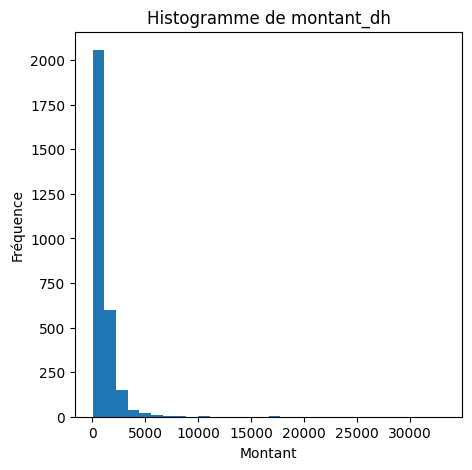

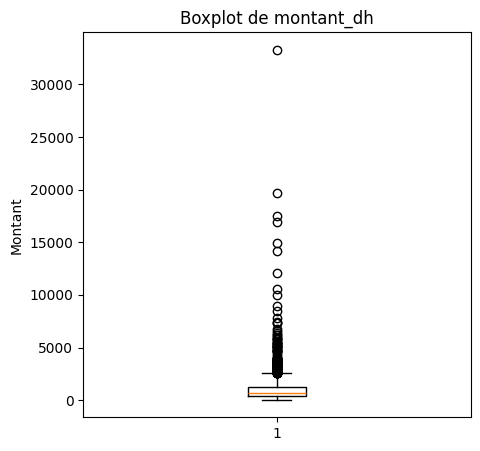

In [52]:
plt.figure(figsize=(5,5))
plt.hist(df["montant_dh"].dropna(),bins=30)
plt.title("Histogramme de montant_dh")
plt.xlabel("Montant")
plt.ylabel("Fréquence")
plt.show()
plt.figure(figsize=(5,5))
plt.boxplot(df["montant_dh"].dropna())
plt.title("Boxplot de montant_dh")
plt.ylabel("Montant")
plt.show()

Question 5 — Répartition des classe

fraude
0    2742
1     258
Name: count, dtype: int64
fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


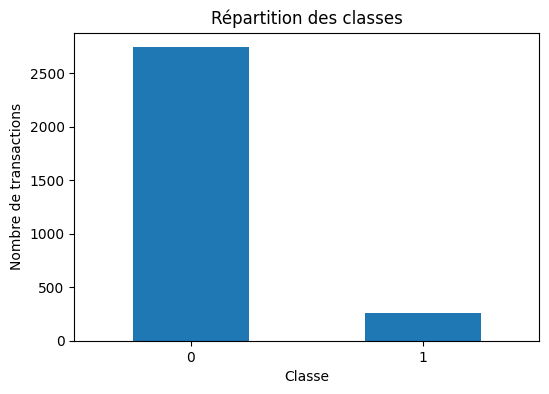

In [16]:
print(df["fraude"].value_counts())
print(df["fraude"].value_counts(normalize=True)*100)
df["fraude"].value_counts().plot(kind="bar",figsize=(6,4))
plt.title("Répartition des classes")
plt.xlabel("Classe")
plt.ylabel("Nombre de transactions")
plt.xticks(rotation=0)
plt.show()

Question 6 — Identifier les variables à exclure

In [17]:
print("Identifiants:")
print(["id_operation","id_client"])
print("Variable à exclure :")
print(["resultat_enquete"])
print(df.columns.tolist())

Identifiants:
['id_operation', 'id_client']
Variable à exclure :
['resultat_enquete']
['id_operation', 'id_client', 'montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international', 'resultat_enquete', 'fraude']


Partie 2 — Séparation et préparation des données

Question 7 — Séparer X et y

In [18]:
y=df["fraude"]
X=df.drop(
    columns=["fraude","id_operation","id_client","resultat_enquete"])
print("Dimensions de X:",X.shape)
print("Dimensions de y:",y.shape)

Dimensions de X: (3000, 8)
Dimensions de y: (3000,)


Question 8 — Séparation référence et vérification

In [19]:
from sklearn.model_selection import train_test_split
X_ref, X_ver, y_ref, y_ver = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Taille de référence:",X_ref.shape)
print("Taille de vérification:",X_ver.shape)
print("Proportion des fraudes dans référence :")
print(y_ref.value_counts(normalize=True))
print("Proportion des fraudes dans vérification :")
print(y_ver.value_counts(normalize=True))

Taille de référence: (2400, 8)
Taille de vérification: (600, 8)
Proportion des fraudes dans référence :
fraude
0    0.914167
1    0.085833
Name: proportion, dtype: float64
Proportion des fraudes dans vérification :
fraude
0    0.913333
1    0.086667
Name: proportion, dtype: float64


Question 9 — Identifier les variables numériques et catégorielles

In [20]:
numeric_cols=["montant_dh","anciennete_mois","nb_ops_24h","heure"]
categorical_cols=["canal","appareil","region","international"]
print("Variables numériques:",numeric_cols)
print("Variables catégorielles:",categorical_cols)

Variables numériques: ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Variables catégorielles: ['canal', 'appareil', 'region', 'international']


Question 10 — Pipeline numérique avec StandardScaler

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
pipeline_num=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])
X_ref_num=pipeline_num.fit_transform(X_ref[numeric_cols])
X_ver_num=pipeline_num.transform(X_ver[numeric_cols])
print("Données numériques de référence :")
print(X_ref_num[:5])

Données numériques de référence :
[[-0.45279558 -0.69683119  0.16959525  0.64756193]
 [-0.36731967  0.55605041  1.38460603  1.64820949]
 [-0.40885247 -0.09059816  0.16959525  1.64820949]
 [ 1.12788371 -1.5657652  -1.65292091 -0.92488425]
 [-0.47146802  0.19231059 -0.43791013  0.07576332]]


Question 11 — Pipeline catégoriel avec OneHotEncoder

In [22]:
from sklearn.preprocessing import OneHotEncoder
pipeline_cat=Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder",OneHotEncoder(handle_unknown="ignore"))])
X_ref_cat=pipeline_cat.fit_transform(X_ref[categorical_cols])
X_ver_cat=pipeline_cat.transform(X_ver[categorical_cols])
print("Dimensions référence:",X_ref_cat.shape)
print("Dimensions vérification:",X_ver_cat.shape)

Dimensions référence: (2400, 14)
Dimensions vérification: (600, 14)


Question 12 — Combiner les deux pipelines

In [23]:
from sklearn.compose import ColumnTransformer
preprocessor=ColumnTransformer([("num",pipeline_num,numeric_cols),("cat",pipeline_cat,categorical_cols)])
X_ref_transformed=preprocessor.fit_transform(X_ref)
X_ver_transformed=preprocessor.transform(X_ver)
print("Dimensions référence :",X_ref_transformed.shape)
print("Dimensions vérification :",X_ver_transformed.shape)

Dimensions référence : (2400, 18)
Dimensions vérification : (600, 18)


Question 13 — Comparer StandardScaler et RobustScaler

In [25]:
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,RobustScaler
pipeline_standard = Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler", StandardScaler())])
pipeline_robust = Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", RobustScaler())])
standard_result = pipeline_standard.fit_transform(X_ref[["montant_dh"]])

robust_result = pipeline_robust.fit_transform(X_ref[["montant_dh"]])
print("StandardScaler :")
print(standard_result[:10])
print("\nRobustScaler :")
print(robust_result[:10])

StandardScaler :
[[-0.45279558]
 [-0.36731967]
 [-0.40885247]
 [ 1.12788371]
 [-0.47146802]
 [-0.27277493]
 [-0.57981937]
 [-0.45162055]
 [-0.46535937]
 [-0.40746653]]

RobustScaler :
[[-0.35673954]
 [-0.21774757]
 [-0.28528385]
 [ 2.21359544]
 [-0.3871027 ]
 [-0.06400882]
 [-0.5632923 ]
 [-0.35482883]
 [-0.37716945]
 [-0.28303019]]


Question 14 — Data Leakage

In [26]:
scaler_bad=StandardScaler()
scaler_bad.fit(X[numeric_cols])
print("Moyennes utilisées:")
print(scaler_bad.mean_)

Moyennes utilisées:
[1028.35945731   88.46038394    2.70580251   11.42766667]


Partie 3 : Détection et traitement des valeurs extrêmes

Question 15 — Calculer Q1, Q3 et IQR

In [27]:
Q1=X_ref["montant_dh"].quantile(0.25)
Q3=X_ref["montant_dh"].quantile(0.75)
IQR=Q3-Q1
print("Q1=",Q1)
print("Q3=",Q3)
print("IQR=",IQR)

Q1= 393.095
Q3= 1249.8775
IQR= 856.7825


Question 16 — Détecter les valeurs extrêmes

In [28]:
limite_inf=Q1-1.5*IQR
limite_sup=Q3+1.5*IQR
outliers=X_ref[(X_ref["montant_dh"]<limite_inf)|(X_ref["montant_dh"]>limite_sup)]
print("Nombre de valeurs extrêmes :",len(outliers))
display(outliers[["montant_dh"]].head(10))

Nombre de valeurs extrêmes : 146


,montant_dh
1601,2940.62
1348,3449.17
2660,33281.23
1489,3988.17
2049,3942.99
2088,2645.74
1105,6733.98
1074,2535.89
396,3002.07
329,5021.72


Question 17 — Comparer les données avant et après Capping

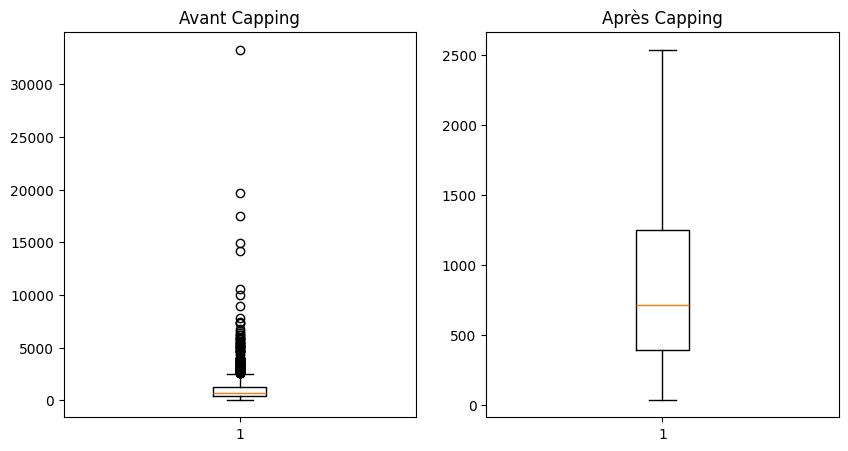

In [29]:
X_ref_capped=X_ref.copy()
X_ref_capped["montant_dh"]=X_ref_capped["montant_dh"].clip(lower=limite_inf,upper=limite_sup)
X_ver_capped=X_ver.copy()
X_ver_capped["montant_dh"]=X_ver_capped["montant_dh"].clip(lower=limite_inf,upper=limite_sup)
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.boxplot(X_ref["montant_dh"].dropna())
plt.title("Avant Capping")
plt.subplot(1,2,2)
plt.boxplot(X_ref_capped["montant_dh"].dropna())
plt.title("Après Capping")
plt.show()

Question 18 — Comparer les trois méthodes de normalisation

In [30]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
imputer=SimpleImputer(strategy="median")
montant_ref=imputer.fit_transform(X_ref[["montant_dh"]])
montant_ver=imputer.transform(X_ver[["montant_dh"]])
scaler_minmax=MinMaxScaler()
minmax_ref=scaler_minmax.fit_transform(montant_ref)
minmax_ver=scaler_minmax.transform(montant_ver)
scaler_standard=StandardScaler()
standard_ref=scaler_standard.fit_transform(montant_ref)
standard_ver=scaler_standard.transform(montant_ver)
scaler_robust=RobustScaler()
robust_ref=scaler_robust.fit_transform(montant_ref)
robust_ver=scaler_robust.transform(montant_ver)
print("MinMaxScaler :")
print(minmax_ref[:5])
print("StandardScaler :")
print(standard_ref[:5])
print("RobustScaler :")
print(robust_ref[:5])

MinMaxScaler :
[[0.0115242 ]
 [0.01493767]
 [0.01327906]
 [0.07464832]
 [0.01077852]]
StandardScaler :
[[-0.45279558]
 [-0.36731967]
 [-0.40885247]
 [ 1.12788371]
 [-0.47146802]]
RobustScaler :
[[-0.35673954]
 [-0.21774757]
 [-0.28528385]
 [ 2.21359544]
 [-0.3871027 ]]


Question 19 — Comparer trois montants normaux et un montant élevé

In [31]:
normal_values=X_ref[X_ref["montant_dh"]<=limite_sup]["montant_dh"].dropna().head(3)
high_value=X_ref[X_ref["montant_dh"]>limite_sup]["montant_dh"].dropna().head(1)
exemple=pd.DataFrame({"montant_dh":list(normal_values)+list(high_value)})
print("Montants originaux:")
print(exemple)
print("MinMaxScaler:")
print(scaler_minmax.transform(exemple))
print("StandardScaler:")
print(scaler_standard.transform(exemple))
print("RobustScaler :")
print(scaler_robust.transform(exemple))

Montants originaux:
   montant_dh
0      419.53
1      533.01
2      477.87
3     2940.62
MinMaxScaler:
[[0.0115242 ]
 [0.01493767]
 [0.01327906]
 [0.08735827]]
StandardScaler:
[[-0.45279558]
 [-0.36731967]
 [-0.40885247]
 [ 1.44615119]]
RobustScaler :
[[-0.35673954]
 [-0.21774757]
 [-0.28528385]
 [ 2.73112867]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RobustScaler was fitted without feature names
  warnings.warn(


Question 20 — Histogrammes des trois transformations

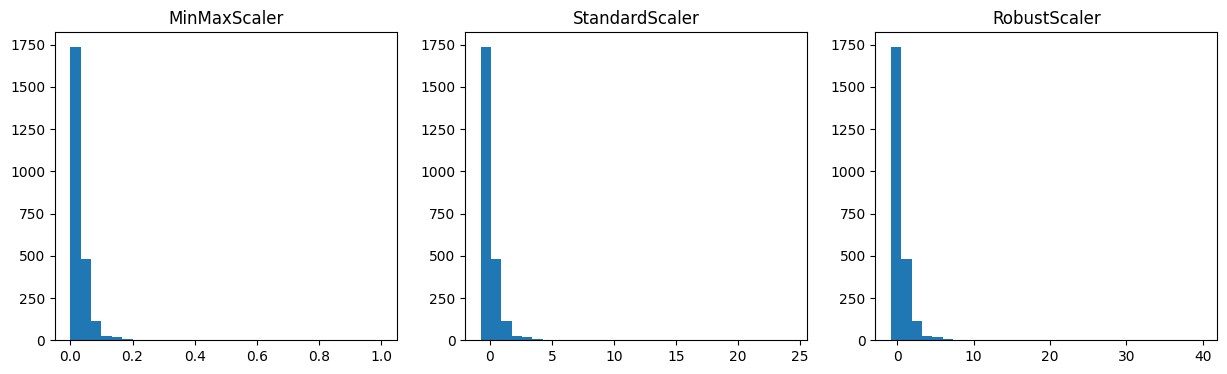

In [32]:
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.hist(minmax_ref,bins=30)
plt.title("MinMaxScaler")
plt.subplot(1,3,2)
plt.hist(standard_ref,bins=30)
plt.title("StandardScaler")
plt.subplot(1,3,3)
plt.hist(robust_ref, bins=30)
plt.title("RobustScaler")
plt.show()

Question 21 — Vérifier une nouvelle transaction supérieure au maximum

In [33]:
max_ref=X_ref["montant_dh"].max()
nouveau_montant=pd.DataFrame({"montant_dh":[max_ref + 1000]})
nouveau_resultat=scaler_minmax.transform(nouveau_montant)
print("Montant maximum de référence:",max_ref)
print("Nouveau montant:",max_ref +1000)
print("Résultat MinMaxScaler:",nouveau_resultat)

Montant maximum de référence: 33281.23
Nouveau montant: 34281.23
Résultat MinMaxScaler: [[1.03007987]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(


Partie 4 : Gestion du déséquilibre des classes

Question 22 — Afficher les classes dans les données de référence

In [34]:
print("Nombre d'exemples par classe:")
print(y_ref.value_counts())
print("Proportion par classe:")
print(y_ref.value_counts(normalize=True)*100)

Nombre d'exemples par classe:
fraude
0    2194
1     206
Name: count, dtype: int64
Proportion par classe:
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64


Question 23 — RandomOverSampler

In [37]:
from imblearn.over_sampling import RandomOverSampler
print("Avant OverSampling:")
print(y_ref.value_counts())
ros=RandomOverSampler(random_state=42)
X_over, y_over=ros.fit_resample(X_ref,y_ref)
print("Après OverSampling:")
print(y_over.value_counts())
print("Dimensions après OverSampling:",X_over.shape)

Avant OverSampling:
fraude
0    2194
1     206
Name: count, dtype: int64
Après OverSampling:
fraude
0    2194
1    2194
Name: count, dtype: int64
Dimensions après OverSampling: (4388, 8)


Question 24 — RandomUnderSampler

In [38]:
from imblearn.under_sampling import RandomUnderSampler
print("Avant UnderSampling:")
print(y_ref.value_counts())
rus=RandomUnderSampler(random_state=42)
X_under,y_under=rus.fit_resample(X_ref,y_ref)
print("Après UnderSampling:")
print(y_under.value_counts())
print("Dimensions après UnderSampling:",X_under.shape)

Avant UnderSampling:
fraude
0    2194
1     206
Name: count, dtype: int64
Après UnderSampling:
fraude
0    206
1    206
Name: count, dtype: int64
Dimensions après UnderSampling: (412, 8)


Question 25 — Exemple manuel de SMOTE

In [39]:

x1=np.array([100,20])
x2=np.array([200,40])
lambda_value=0.5
x_new=x1 +lambda_value*(x2-x1)
print("Premier exemple :",x1)
print("Deuxième exemple :",x2)
print("Nouvel exemple synthétique:",x_new)

Premier exemple : [100  20]
Deuxième exemple : [200  40]
Nouvel exemple synthétique: [150.  30.]


Question 26 — SMOTE et variables catégorielles

In [40]:
print("Variables catégorielles:")
print(categorical_cols)
print("Variables numériques:")
print(numeric_cols)

Variables catégorielles:
['canal', 'appareil', 'region', 'international']
Variables numériques:
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']


Question 27 — Comparer les méthodes de rééquilibrage

In [41]:
comparison=pd.DataFrame({
    "Avant":y_ref.value_counts(),
    "OverSampling":y_over.value_counts(),
    "UnderSampling":y_under.value_counts()})
print(comparison)

        Avant  OverSampling  UnderSampling
fraude                                    
0        2194          2194            206
1         206          2194            206


Partie 5 : Pipeline final et sauvegarde

Question 28 — Construire le prétraitement final

In [42]:
final_num_pipeline=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",RobustScaler())])
final_cat_pipeline = Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("encoder",OneHotEncoder(handle_unknown="ignore"))])
final_preprocessor = ColumnTransformer([("num", final_num_pipeline, numeric_cols),("cat", final_cat_pipeline, categorical_cols)])

Question 29 — Apprentissage et transformation finale

In [43]:
X_ref_final=final_preprocessor.fit_transform(X_ref)
X_ver_final=final_preprocessor.transform(X_ver)
print("Dimensions référence :",X_ref_final.shape)
print("Dimensions vérification :",X_ver_final.shape)
if hasattr(X_ref_final,"toarray"):
    ref_array=X_ref_final.toarray()
else:
    ref_array=np.asarray(X_ref_final)

if hasattr(X_ver_final, "toarray"):
    ver_array=X_ver_final.toarray()
else:
    ver_array=np.asarray(X_ver_final)

print("Valeurs manquantes référence:",np.isnan(ref_array).sum())
print("Valeurs manquantes vérification:",np.isnan(ver_array).sum())

Dimensions référence : (2400, 18)
Dimensions vérification : (600, 18)
Valeurs manquantes référence: 0
Valeurs manquantes vérification: 0


Question 30 — Tester une catégorie inconnue

In [45]:
nouvelle_transaction=X_ver.iloc[[0]].copy()
nouvelle_transaction["canal"]=nouvelle_transaction["canal"].astype(object)
nouvelle_transaction.loc[nouvelle_transaction.index[0],"canal"]="NOUVEAU_CANAL"
resultat_inconnu=final_preprocessor.transform(nouvelle_transaction)
print("Transformation réussie.")
print("Résultat:")
print(resultat_inconnu)

Transformation réussie.
Résultat:
[[ 0.10375406 -0.29761905 -1.          0.30769231  0.          0.
   0.          0.          0.          1.          0.          0.
   0.          1.          0.          0.          0.          1.        ]]


Question 31 — Sauvegarder et recharger le pipeline

In [46]:
import joblib
joblib.dump(final_preprocessor,"preprocessor.pkl")
print("Préprocesseur sauvegardé.")
preprocessor_loaded=joblib.load("preprocessor.pkl")
X_test_loaded=preprocessor_loaded.transform(X_ver)
if hasattr(X_test_loaded,"toarray"):
    X_test_loaded=X_test_loaded.toarray()
if hasattr(X_ver_final,"toarray"):
    X_ver_compare=X_ver_final.toarray()
else:
    X_ver_compare = np.asarray(X_ver_final)
print("Résultats identiques:",np.allclose(X_test_loaded, X_ver_compare))

Préprocesseur sauvegardé.
Résultats identiques: True


Question 32 — Résumé final du TP

In [49]:
print("RAPPORT FINAL")
print("Nombre de doublons supprimés:",nb_doublons)
print("Valeurs manquantes:")
print(df.isnull().sum())
print("Nombre de valeurs extrêmes:",len(outliers))
print("Dimensions des données de référence :")
print(X_ref.shape)
print("Dimensions après prétraitement:")
print(X_ref_final.shape)
print("Répartition des classes avant OverSampling:")
print(y_ref.value_counts())
print("Répartition des classes après OverSampling:")
print(y_over.value_counts())
print("Répartition des classes après UnderSampling:")
print(y_under.value_counts())
print("Préprocesseur final sauvegardé dans preprocessor.pkl")



RAPPORT FINAL
Nombre de doublons supprimés: 45
Valeurs manquantes:
id_operation          0
id_client             0
montant_dh          107
anciennete_mois     135
nb_ops_24h           53
heure                 0
canal               156
appareil            120
region              102
international         0
resultat_enquete      0
fraude                0
dtype: int64
Nombre de valeurs extrêmes: 146
Dimensions des données de référence :
(2400, 8)
Dimensions après prétraitement:
(2400, 18)
Répartition des classes avant OverSampling:
fraude
0    2194
1     206
Name: count, dtype: int64
Répartition des classes après OverSampling:
fraude
0    2194
1    2194
Name: count, dtype: int64
Répartition des classes après UnderSampling:
fraude
0    206
1    206
Name: count, dtype: int64
Préprocesseur final sauvegardé dans preprocessor.pkl
